# Notebook 07 — Validación avanzada

| Parte | Tema | Pregunta |
|---|---|---|
| 1 | Calibración por segmento | ¿La PD calibrada es confiable dentro de cada segmento y de cada grado? ¿Hay una calibración mejor? |
| 2 | Incertidumbre (MC Dropout) | ¿Se pueden identificar las predicciones menos confiables? |
| 3 | Estabilidad del Gini (validación cruzada) | ¿Cuánto varía la performance según la muestra? |
| 4 | Dependencia parcial en unidades reales | ¿Las relaciones aprendidas tienen sentido de negocio? |
| 5 | Concentración sectorial | ¿Dónde se concentra la exposición? ¿El modelo está calibrado por sector? |

In [1]:
import os, sys
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())

import json, pickle, warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import xgboost as xgb
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import brier_score_loss, roc_auc_score
from sklearn.model_selection import StratifiedKFold

from src.config import load_policy
from src.models.calibration import PlattCalibrator
from src.models.pd_model import PDScorer
from src.validation.master_scale import master_scale_table
from src.validation.model_validation import age_groups, expected_calibration_error

plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
gini = lambda y, s: round(2 * roc_auc_score(y, s) - 1, 4)

policy   = load_policy()
scorer   = PDScorer()
X_train  = pd.read_parquet('data/processed/X_train.parquet')
X_test   = pd.read_parquet('data/processed/X_test.parquet')
y_train  = pd.read_parquet('data/processed/y_train.parquet').iloc[:, 0]
y_test   = pd.read_parquet('data/processed/y_test.parquet').iloc[:, 0].values
raw_test = pd.read_parquet('data/processed/test.parquet')
splits   = np.load('data/processed/train_splits.npz')

raw_score = scorer.raw_score(X_test)
pd_test   = scorer.calibrator.transform(raw_score)
gini_global = gini(y_test, pd_test)
print(f'Gini test: {gini_global} | default real {y_test.mean():.2%} | PD media {pd_test.mean():.2%}')

Gini test: 0.5176 | default real 8.07% | PD media 7.94%


---
## Parte 1 — Calibración por segmento y por grado

Que la calibración global esté bien no implica que esté bien dentro de cada segmento.
Si el modelo dice 15% en un segmento y el default real es 30%, ese segmento queda
subprovisionado.

In [2]:
seg = pd.DataFrame({'y': y_test, 'raw': raw_score, 'pd': pd_test,
                    'genero': raw_test['CODE_GENDER'].values,
                    'edad': age_groups(raw_test['age_years']).values,
                    'ingreso': raw_test['NAME_INCOME_TYPE'].values})
filas = []
for col in ['genero', 'edad', 'ingreso']:
    for g, d in seg.groupby(col):
        if len(d) < 1000: continue
        filas.append({'segmento': f'{col}={g}', 'n': len(d), 'default_real': d['y'].mean(),
                      'score_crudo': d['raw'].mean(), 'pd_calibrada': d['pd'].mean(),
                      'gap_rel_calibrada': d['pd'].mean() / d['y'].mean() - 1})
cal_seg = pd.DataFrame(filas).set_index('segmento')
cal_seg.style.format({'default_real': '{:.2%}', 'score_crudo': '{:.2%}', 'pd_calibrada': '{:.2%}',
                      'gap_rel_calibrada': '{:+.1%}'})

,n,default_real,score_crudo,pd_calibrada,gap_rel_calibrada
segmento,,,,,
genero=F,40561,6.99%,36.94%,7.30%,+4.4%
genero=M,20940,10.17%,42.46%,9.19%,-9.6%
edad=25-35,14389,10.51%,45.96%,10.37%,-1.4%
edad=35-45,16838,8.28%,39.42%,8.21%,-1.0%
edad=45-55,14057,7.33%,36.74%,7.13%,-2.8%
edad=<25,2422,11.73%,51.63%,12.21%,+4.1%
edad=>55,13797,5.38%,30.52%,5.17%,-3.8%
ingreso=Commercial associate,14344,7.06%,37.14%,7.37%,+4.5%
ingreso=Pensioner,11228,5.50%,31.55%,5.38%,-2.0%


### Platt vs isotónica

Las dos se ajustan sobre el split de calibración (24.601 filas que el modelo no vio) y se
evalúan en test. El foco está en el **backtest por grado**: con Platt, el grado G
(PD ≥ 27%) quedó en rojo en el pipeline, porque el modelo subestima el riesgo más alto.

In [3]:
cal_idx = splits['cal']
raw_cal = scorer.raw_score(X_train.iloc[cal_idx])
y_cal   = y_train.values[cal_idx]

platt = PlattCalibrator().fit(raw_cal, y_cal)
iso   = IsotonicRegression(out_of_bounds='clip', y_min=1e-4, y_max=0.999).fit(raw_cal, y_cal)
cands = {'Platt (pipeline)': platt.transform(raw_score), 'Isotónica': iso.predict(raw_score)}

ms = policy['master_scale']
resumen, tablas = [], {}
for name, p in cands.items():
    t = master_scale_table(y_test, p, ms['limites_superiores'], ms['grados'])
    tablas[name] = t
    resumen.append({'método': name, 'Brier': brier_score_loss(y_test, p),
                    'ECE': expected_calibration_error(y_test, p), 'Gini': gini(y_test, p),
                    'grados en rojo': ', '.join(t.loc[t.result == 'subestima', 'grade']) or 'ninguno',
                    'grados en ámbar': ', '.join(t.loc[t.result == 'alerta', 'grade']) or 'ninguno'})
display(pd.DataFrame(resumen).set_index('método').round(4))
for name, t in tablas.items():
    print(name)
    print(t[['grade', 'n', 'pd_avg', 'default_rate', 'p_jeffreys', 'result']].to_string(index=False))
    print()

,Brier,ECE,Gini,grados en rojo,grados en ámbar
método,,,,,
Platt (pipeline),0.0677,0.0045,0.5176,G,F
Isotónica,0.0678,0.0052,0.5154,G,ninguno


Platt (pipeline)
grade     n  pd_avg  default_rate  p_jeffreys    result
    A  8595  0.0134        0.0144      0.2118        ok
    B 14441  0.0296        0.0274      0.9495        ok
    C 14392  0.0535        0.0532      0.5806        ok
    D 10060  0.0880        0.0880      0.5005        ok
    E  7337  0.1358        0.1375      0.3338        ok
    F  4587  0.2107        0.2208      0.0466    alerta
    G  2091  0.3458        0.3702      0.0098 subestima

Isotónica
grade     n  pd_avg  default_rate  p_jeffreys    result
    A  9060  0.0126        0.0145      0.0588        ok
    B 18701  0.0312        0.0319      0.2935        ok
    C 10612  0.0580        0.0596      0.2288        ok
    D  6473  0.0899        0.0851      0.9099        ok
    E 11062  0.1352        0.1310      0.9002        ok
    F  3724  0.2317        0.2403      0.1067        ok
    G  1871  0.3368        0.3789      0.0001 subestima



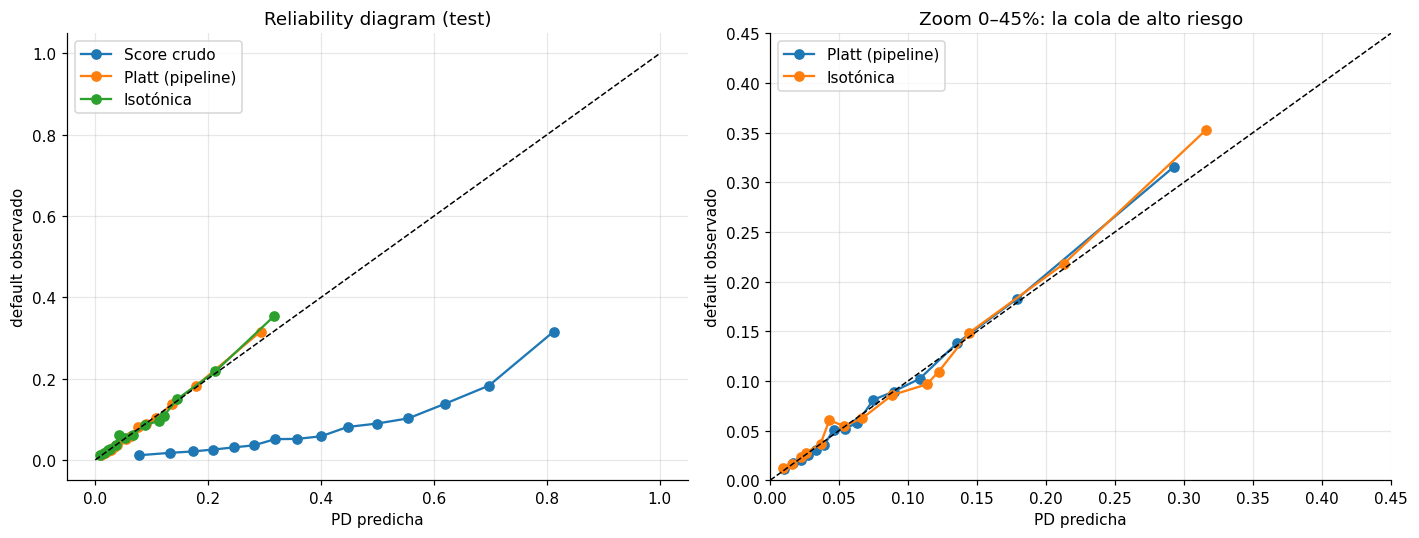

In [4]:
from sklearn.calibration import calibration_curve
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for name, p in [('Score crudo', raw_score)] + list(cands.items()):
    pt, pp = calibration_curve(y_test, p, n_bins=15, strategy='quantile')
    axes[0].plot(pp, pt, 'o-', label=name)
axes[0].plot([0, 1], [0, 1], 'k--', lw=1); axes[0].set_title('Reliability diagram (test)')
for name, p in cands.items():
    pt, pp = calibration_curve(y_test, p, n_bins=15, strategy='quantile')
    axes[1].plot(pp, pt, 'o-', label=name)
axes[1].plot([0, .45], [0, .45], 'k--', lw=1); axes[1].set_xlim(0, .45); axes[1].set_ylim(0, .45)
axes[1].set_title('Zoom 0–45%: la cola de alto riesgo')
for ax in axes:
    ax.set_xlabel('PD predicha'); ax.set_ylabel('default observado'); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig('reports/figures/calibration_advanced.png', dpi=150, bbox_inches='tight'); plt.show()

### Calibración

**Por segmento.** La PD calibrada está dentro de ±5% en casi todos los segmentos, con una
excepción relevante: **género**.
- **Hombres:** PD media 9,19% vs default real 10,17%, es decir **−9,6%**. Con n = 20.940 la
  diferencia es de unos 4,7 errores estándar.
- **Mujeres:** PD 7,30% vs 6,99%, **+4,4%**.

Es una consecuencia directa de excluir el género del modelo. La PD se calcula "a ciegas" del
género, así que el promedio se reparte y las mujeres terminan pagando un precio de riesgo
algo mayor que el suyo, y los hombres, uno menor. Es la tensión clásica entre *fairness through
unawareness* y *calibración por grupo*: no se pueden cumplir las dos a la vez cuando las tasas
base difieren. La decisión de cuál priorizar es de política, no técnica, pero hay que
documentarla.

**Platt vs isotónica.**
- Las dos tienen Brier y ECE prácticamente iguales.
- La isotónica pierde un poco de Gini (0,515 vs 0,518) porque genera empates.
- La isotónica corrige el grado F (de ámbar a ok), pero **no el grado G: lo empeora**
  (p = 0,0001).

Entonces, el problema del grado G no es la forma de la función de calibración: la cola de
alto riesgo es más riesgosa de lo que el modelo puede distinguir con estos datos.

**Recomendación:**
- aplicar un **margen de conservadurismo** en los grados F–G (por ejemplo, llevar la PD al
  límite superior del IC del default observado);
- re-testear;
- mantener Platt por simplicidad y porque preserva el Gini.

> **Seguimiento.** Implementado en el champion v1.1 (`src/models/moc.py`,
> [ADR 0007](../docs/decisions/0007-pd-de-grado-con-moc.md)). La PD de grado = máx(PD media,
> percentil 75 de Jeffreys del default observado en validación) pasa el backtest en todos los
> grados (G: p 0,0098 → 0,68).

---
## Parte 2 — Incertidumbre con Monte Carlo Dropout

Se mantiene el Dropout activo en inferencia sobre la red neuronal de la notebook 06, y se
predice 50 veces por cliente. El desvío entre pasadas mide la incertidumbre del modelo
(epistémica). La pregunta práctica es si ese desvío identifica a los clientes donde el
**champion (XGBoost)** ordena peor, para mandarlos a revisión humana.

In [5]:
class CreditRiskNet(nn.Module):
    def __init__(self, input_dim, hidden_dims=(256, 128, 64), dropout=0.3):
        super().__init__()
        layers, prev = [], input_dim
        for h in hidden_dims:
            layers += [nn.Linear(prev, h), nn.BatchNorm1d(h), nn.ReLU(), nn.Dropout(dropout)]
            prev = h
        layers.append(nn.Linear(prev, 1))
        self.network = nn.Sequential(*layers)
    def forward(self, x):
        return torch.sigmoid(self.network(x)).squeeze(1)

torch.manual_seed(0)
nn_model = CreditRiskNet(X_test.shape[1])
nn_model.load_state_dict(torch.load('models/dl/tabular_nn.pt', map_location='cpu'))
nn_model.eval()
for m in nn_model.modules():
    if isinstance(m, nn.Dropout):
        m.train()
X_t = torch.FloatTensor(np.nan_to_num(X_test.values.astype(np.float32)))
with torch.no_grad():
    passes = np.stack([np.concatenate([nn_model(X_t[i:i+8192]).numpy() for i in range(0, len(X_t), 8192)])
                       for _ in range(50)])
mc_std = passes.std(axis=0)

q = pd.qcut(mc_std, 4, labels=['Q1 (baja)', 'Q2', 'Q3', 'Q4 (alta)'])
unc = pd.DataFrame({'y': y_test, 'pd': pd_test, 'q': q}).groupby('q', observed=True).apply(
    lambda d: pd.Series({'n': len(d), 'pd_media': d['pd'].mean(), 'default_real': d['y'].mean(),
                         'gini_xgboost': gini(d['y'], d['pd'])}))
display(unc.round(4))
top5 = mc_std >= np.quantile(mc_std, 0.95)
print(f'5% más incierto: Gini XGBoost {gini(y_test[top5], pd_test[top5])} vs resto {gini(y_test[~top5], pd_test[~top5])}')

,n,pd_media,default_real,gini_xgboost
q,,,,
Q1 (baja),15376.0,0.0888,0.0915,0.6293
Q2,15376.0,0.0889,0.0912,0.5158
Q3,15375.0,0.0787,0.0810,0.4584
Q4 (alta),15376.0,0.0613,0.0592,0.3654


5% más incierto: Gini XGBoost 0.3207 vs resto 0.5224


### Incertidumbre

**La incertidumbre de la red sí identifica dónde el champion ordena peor.**

| Cuartil de incertidumbre (MC Dropout) | Gini de XGBoost |
|---|---:|
| Q1 (baja) | 0,629 |
| Q2 | 0,516 |
| Q3 | 0,458 |
| Q4 (alta) | 0,365 |
| 5% más incierto | **0,321** |
| Resto | 0,522 |

Las tasas de default de los cuartiles son parecidas (6–9%): la incertidumbre no identifica
a los clientes más riesgosos, sino a aquellos **sobre los que el modelo sabe menos**.

**Uso propuesto.** Mandar a revisión manual al 5% de mayor incertidumbre. Sería una regla
complementaria a la banda de ±3 pp alrededor del cutoff (notebook 04): ésa captura decisiones
frágiles, ésta captura clientes difíciles de ordenar. A diferencia del autoencoder (notebook
06), esta señal sí separa.

---
## Parte 3 — Estabilidad del Gini: validación cruzada 5-fold

> **Por qué se reemplazó el "backtesting temporal" anterior.** La versión previa ordenaba el
> train por `DAYS_BIRTH` (que es la edad, no una fecha) y además cortaba `X_train`, que no
> estaba reordenado. Las "ventanas" eran cortes aleatorios. Home Credit no trae fecha de
> originación, así que un backtest temporal honesto **no es posible** con este dataset.

Lo que sí se puede medir es cuánto varía el Gini según la muestra. Se re-entrena XGBoost con
la misma configuración y el número de árboles del champion en 5 folds del train.

In [6]:
params = scorer.model.get_params()
params.update(n_estimators=scorer.model.best_iteration + 1, early_stopping_rounds=None)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv = []
for k, (tr, va) in enumerate(skf.split(X_train, y_train), 1):
    m = xgb.XGBClassifier(**params).fit(X_train.iloc[tr], y_train.iloc[tr], verbose=False)
    cv.append(gini(y_train.iloc[va], m.predict_proba(X_train.iloc[va])[:, 1]))
    print(f'  fold {k}: Gini {cv[-1]}')
cv = np.array(cv)
print(f'\nGini CV: {cv.mean():.4f} ± {cv.std(ddof=1):.4f} (rango {cv.min():.4f}–{cv.max():.4f}) | test: {gini_global}')

  fold 1: Gini 0.5102
  fold 2: Gini 0.511
  fold 3: Gini 0.5132
  fold 4: Gini 0.5152
  fold 5: Gini 0.5139

Gini CV: 0.5127 ± 0.0021 (rango 0.5102–0.5152) | test: 0.5176


### Estabilidad

**El Gini es estable entre muestras:** 0,513 ± 0,002 en 5 folds (rango 0,510–0,515). El
Gini de test (0,518) queda apenas por encima del rango; el IC bootstrap del test
(0,503–0,532) lo contiene. La performance no depende de una partición favorable.

**Lo que esto no prueba:** la estabilidad en el tiempo. Todas las particiones mezclan el mismo
período. Con datos reales, el paso siguiente es un backtest por cosecha de originación
(entrenar hasta T, evaluar en T+12 meses).

---
## Parte 4 — Dependencia parcial en unidades reales

Se fija una variable *cruda* en distintos valores para una muestra de 1.000 clientes, se
recalculan los ratios, y se promedia la PD calibrada. La versión anterior graficaba sobre
features estandarizadas (z-scores), que no se pueden leer en términos de negocio.

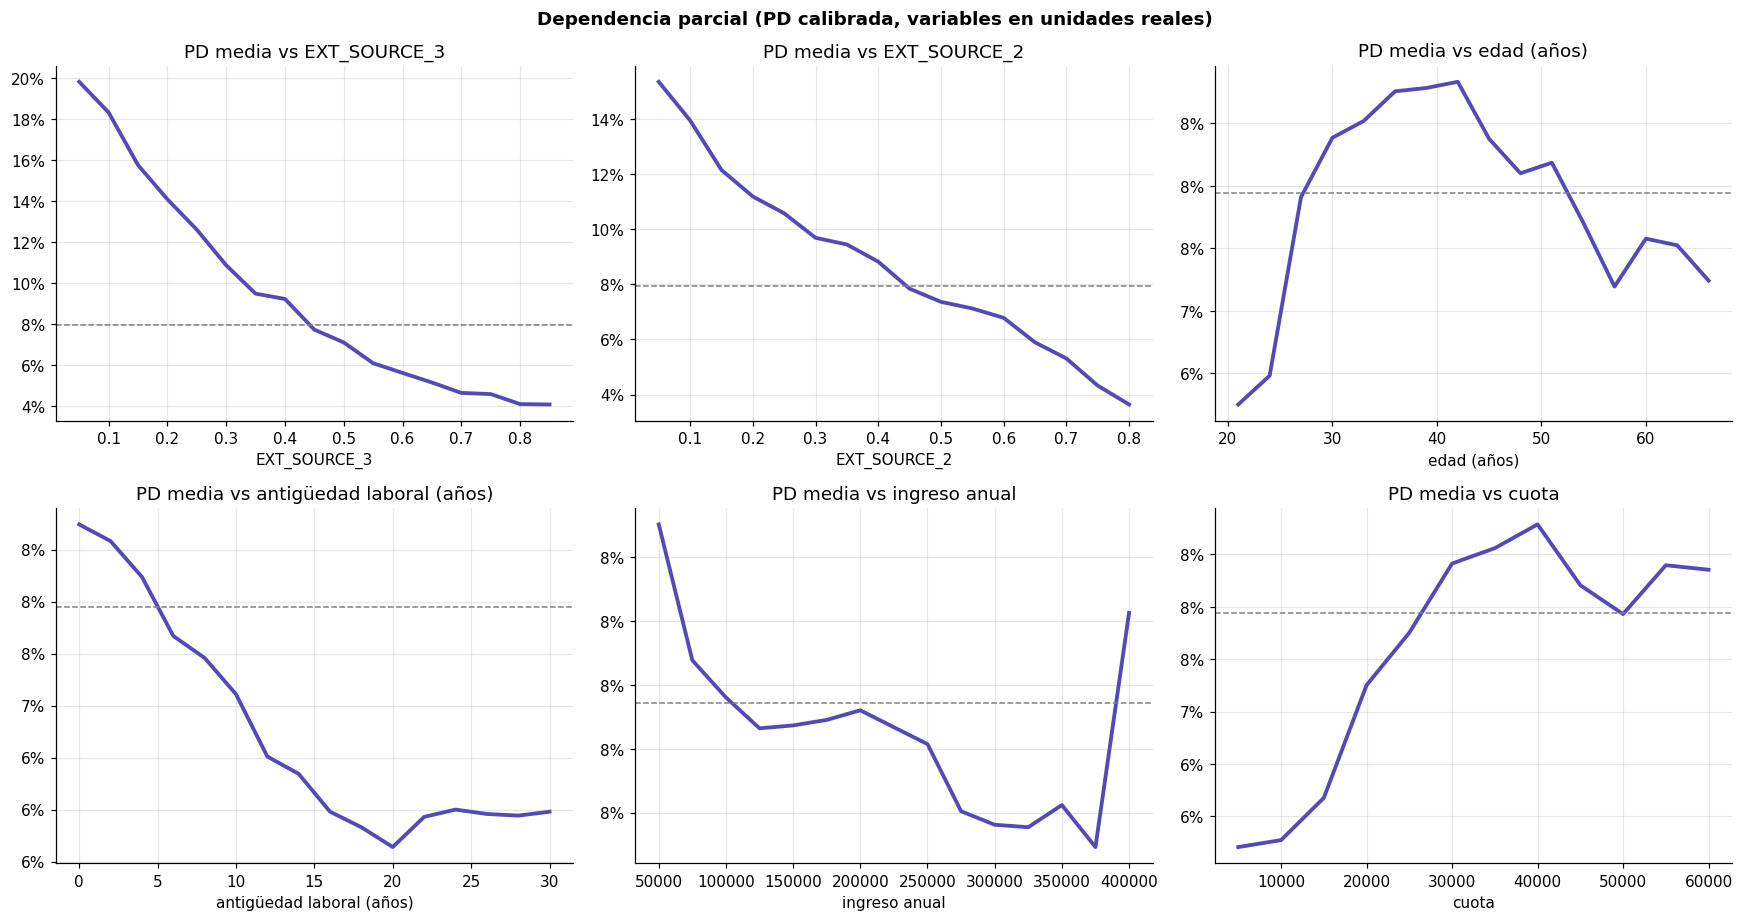

EXT_SOURCE_3                 PD de 19.81% (x=0.05) a 4.08% (x=0.85) | monótona: True
EXT_SOURCE_2                 PD de 15.35% (x=0.05) a 3.64% (x=0.80) | monótona: True
edad (años)                  PD de 6.25% (x=21.00) a 7.24% (x=66.00) | monótona: False
antigüedad laboral (años)    PD de 8.74% (x=0.00) a 5.98% (x=30.00) | monótona: False
ingreso anual                PD de 8.50% (x=50,000.00) a 8.23% (x=400,000.00) | monótona: False
cuota                        PD de 5.71% (x=5,000.00) a 8.35% (x=60,000.00) | monótona: False


In [7]:
muestra = raw_test.sample(1000, random_state=42).reset_index(drop=True)

def pdp(col, valores, transform=lambda v: v):
    out = []
    for v in valores:
        d = muestra.copy(); d[col] = transform(v)
        out.append(scorer.pd_from_raw(d).mean())
    return np.array(out)

specs = [
    ('EXT_SOURCE_3', np.linspace(0.05, 0.85, 17), lambda v: v, 'EXT_SOURCE_3'),
    ('EXT_SOURCE_2', np.linspace(0.05, 0.80, 16), lambda v: v, 'EXT_SOURCE_2'),
    ('DAYS_BIRTH', np.arange(21, 69, 3), lambda v: -v * 365, 'edad (años)'),
    ('DAYS_EMPLOYED', np.arange(0, 31, 2), lambda v: -v * 365 - 1, 'antigüedad laboral (años)'),
    ('AMT_INCOME_TOTAL', np.linspace(50_000, 400_000, 15), lambda v: v, 'ingreso anual'),
    ('AMT_ANNUITY', np.linspace(5_000, 60_000, 12), lambda v: v, 'cuota'),
]
fig, axes = plt.subplots(2, 3, figsize=(16, 8.5))
pdp_res = {}
for ax, (col, vals, tf, label) in zip(axes.ravel(), specs):
    curva = pdp(col, vals, tf)
    pdp_res[label] = (vals, curva)
    ax.plot(vals, curva, color='#534AB7', lw=2.5)
    ax.axhline(pd_test.mean(), color='gray', ls='--', lw=1)
    ax.set_title(f'PD media vs {label}'); ax.set_xlabel(label); ax.grid(alpha=0.3)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
plt.suptitle('Dependencia parcial (PD calibrada, variables en unidades reales)', fontweight='bold')
plt.tight_layout(); plt.savefig('reports/figures/pdp_top_features.png', dpi=150, bbox_inches='tight'); plt.show()
for label, (vals, curva) in pdp_res.items():
    print(f'{label:<28} PD de {curva[0]:.2%} (x={vals[0]:,.2f}) a {curva[-1]:.2%} (x={vals[-1]:,.2f}) | '
          f'monótona: {bool(np.all(np.diff(curva) <= 1e-4) or np.all(np.diff(curva) >= -1e-4))}')

### Dependencia parcial

**Relaciones con sentido de negocio:**
- **EXT_SOURCE_3 y EXT_SOURCE_2:** monótonas y fuertes. La PD media baja de 19,8% a 4,1% a
  lo largo del rango de EXT_SOURCE_3.
- **Antigüedad laboral:** la PD baja de 8,7% (0 años) a 5,3% (21 años) y después se aplana.
- **Cuota:** la PD sube de 5,7% a ~8,5%, aunque no de forma estrictamente monótona.
- **Ingreso:** prácticamente plano (8,5% → 8,2%). Es consistente con el stress test: el
  modelo casi no usa el nivel de ingreso.

**El hallazgo importante es la edad.** Con el resto de las variables fijo, la PD tiene forma
de U invertida: 6,3% a los 21, máximo de 8,8% a los 39 y 7,2% a los 57. **La variable edad
no penaliza a los jóvenes.** La diferencia de default por edad del EDA (12,3% vs 5,2%) llega
al modelo a través de los scores de bureau, que tienen una correlación de 0,60 con la edad.
Es la tercera evidencia del mismo fenómeno, junto con el EDA y el SHAP de la notebook 03.

**Advertencia de método.** Un PDP fija una variable sin mover las correlacionadas. "Un
cliente de 21 años con el EXT_SOURCE_1 de uno de 60" es una combinación poco realista, así
que los extremos de la curva de edad deben leerse con cuidado.

---
## Parte 5 — Concentración sectorial

> **Por qué se sacó la sección de GNN.** La versión anterior armaba un grafo conectando
> clientes al azar dentro del mismo decil de ingreso. Esas aristas no representan ninguna
> relación real (empleador, garante, transacciones), así que no podía medir contagio, y el
> GCN dio un Gini de 0,065. Para analizar dependencia entre clientes, Home Credit sólo ofrece
> una aproximación con datos reales: el **sector del empleador** (`ORGANIZATION_TYPE`).

Se analizan tres cosas por sector:
- cuánta exposición concentra (HHI);
- si el modelo está calibrado (un sector subestimado indica un factor de riesgo común que el
  modelo no captura);
- qué pasa si un sector entero sufre un shock.

In [8]:
sec = pd.DataFrame({'sector': raw_test['ORGANIZATION_TYPE'].str.replace(r':? ?[Tt]ype \d+', '', regex=True),
                    'ead': raw_test['AMT_CREDIT'].values, 'y': y_test, 'pd': pd_test})
g = sec.groupby('sector').agg(n=('y', 'size'), exposicion=('ead', 'sum'), default_real=('y', 'mean'), pd_media=('pd', 'mean'))
g['share_exposicion'] = g['exposicion'] / g['exposicion'].sum()
g['gap_rel'] = g['pd_media'] / g['default_real'] - 1
from scipy import stats
g['p_subestima'] = [stats.beta.cdf(r.pd_media, r.default_real * r.n + 0.5, r.n - r.default_real * r.n + 0.5) for r in g.itertuples()]
g = g.sort_values('share_exposicion', ascending=False)
hhi = (g['share_exposicion'] ** 2).sum()
print(f'Sectores: {len(g)} | HHI de exposición: {hhi:.3f} (equivalente a {1/hhi:.1f} sectores de igual tamaño)')
print(f'Top 3 sectores: {g["share_exposicion"].head(3).sum():.1%} de la exposición')
grandes = g[g['n'] >= 500]
print(f'\nSectores con n >= 500 donde la PD subestima significativamente (Jeffreys p < 1%):')
print(grandes[grandes['p_subestima'] < 0.01][['n', 'default_real', 'pd_media', 'gap_rel']].round(4).to_string() or 'ninguno')
g.head(12)[['n', 'share_exposicion', 'default_real', 'pd_media', 'gap_rel']].style.format(
    {'share_exposicion': '{:.1%}', 'default_real': '{:.2%}', 'pd_media': '{:.2%}', 'gap_rel': '{:+.1%}'})

Sectores: 35 | HHI de exposición: 0.137 (equivalente a 7.3 sectores de igual tamaño)
Top 3 sectores: 57.4% de la exposición

Sectores con n >= 500 donde la PD subestima significativamente (Jeffreys p < 1%):
Empty DataFrame
Columns: [n, default_real, pd_media, gap_rel]
Index: []


,n,share_exposicion,default_real,pd_media,gap_rel
sector,,,,,
Business Entity,16842,28.4%,9.18%,9.02%,-1.7%
XNA,11231,16.4%,5.52%,5.39%,-2.4%
Self-employed,7840,12.6%,10.03%,9.67%,-3.5%
Other,3376,5.6%,8.23%,7.59%,-7.9%
Trade,2870,4.7%,9.34%,8.83%,-5.4%
Industry,2789,4.6%,8.78%,8.73%,-0.6%
Medicine,2208,3.7%,5.93%,6.52%,+10.0%
Government,2063,3.5%,7.42%,7.18%,-3.2%
Transport,1786,3.0%,9.97%,9.31%,-6.6%


In [9]:
# Escenario: el sector más grande (excluyendo XNA = sin empleo formal) sufre un shock
# y su PD se duplica. ¿Cuánto sube la pérdida esperada de la cartera?
lgd = policy['mercados'][policy['mercado_referencia']]['lgd']
el_base = (sec['pd'] * lgd * sec['ead']).sum()
for s in [x for x in g.index if x != 'XNA'][:3]:
    pd_s = np.where(sec['sector'] == s, np.minimum(sec['pd'] * 2, 1), sec['pd'])
    print(f'PD x2 en "{s}" ({g.loc[s, "share_exposicion"]:.1%} de la exposición) -> '
          f'pérdida esperada {((pd_s * lgd * sec["ead"]).sum() / el_base - 1):+.1%}')

PD x2 en "Business Entity" (28.4% de la exposición) -> pérdida esperada +31.3%
PD x2 en "Self-employed" (12.6% de la exposición) -> pérdida esperada +15.1%
PD x2 en "Other" (5.6% de la exposición) -> pérdida esperada +5.3%


### Concentración

**Concentración moderada:**
- **HHI de exposición: 0,137**, equivalente a ~7 sectores de igual tamaño.
- **Top 3:** "Business Entity" (28%), sin empleo formal / XNA (16%) y "Self-employed" (13%)
  suman el 57%.

**Sin subestimación sistemática por sector.** Ningún sector con al menos 500 casos tiene una
PD significativamente por debajo de su default observado (Jeffreys p < 1%). Los desvíos están
entre −8% y +10%, dentro de lo esperable por ruido. No aparece un factor de riesgo sectorial
común que el modelo no capture.

**Escenario de concentración.** Si la PD de "Business Entity" se duplica, la pérdida
esperada de la cartera sube **+31%**: casi tanto como el escenario de recesión combinada del
pipeline (+36%), por un único sector. Es el riesgo de concentración que un modelo de scoring
individual no ve, y justifica límites o monitoreo por sector.

**Limitación.** `ORGANIZATION_TYPE` es una aproximación gruesa: no identifica al empleador,
sólo el tipo de organización. Un análisis de correlación de defaults (en la línea del modelo
de Vasicek/ASRF) requeriría series temporales de default por sector, que Home Credit no tiene.

## Parte 6 — Resumen de la validación avanzada

| Parte | Resultado | Consecuencia |
|---|---|---|
| Calibración por segmento | Hombres −9,6%, mujeres +4,4% | Documentar el trade-off entre ignorar el género y calibrar por grupo |
| Platt vs isotónica | Ninguna corrige el grado G | Margen de conservadurismo en F–G |
| MC Dropout | 5% más incierto: Gini 0,32 vs 0,52 | Revisión manual del 5% más incierto |
| CV 5-fold | Gini 0,513 ± 0,002 | Performance estable entre muestras (no prueba estabilidad temporal) |
| Dependencia parcial | Edad sin penalización directa a jóvenes; ingreso plano | El canal del sesgo por edad es el bureau |
| Concentración | HHI 0,137; Business Entity ×2 → pérdida esperada +31% | Límites y monitoreo por sector |

**Arquitectura recomendada para producción:**
1. XGBoost + Platt con margen de conservadurismo en los grados altos.
2. Revisión manual de:
   - la banda de ±3 pp alrededor del cutoff;
   - el 5% de mayor incertidumbre (MC Dropout).
3. Challenger: stack XGBoost + LSTM de pagos (notebook 06), a validar formalmente.
4. Monitoreo según la notebook 05: PSI mensual, calibración por cosecha, backtest por grado
   y fairness.